/var/folders/s_/l_pk1qz149b9jtwyjblyql3h0000gn/T/ipykernel_80942/2932265687.py:23: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['weekday'] = df['pickup_datetime'].dt.weekday


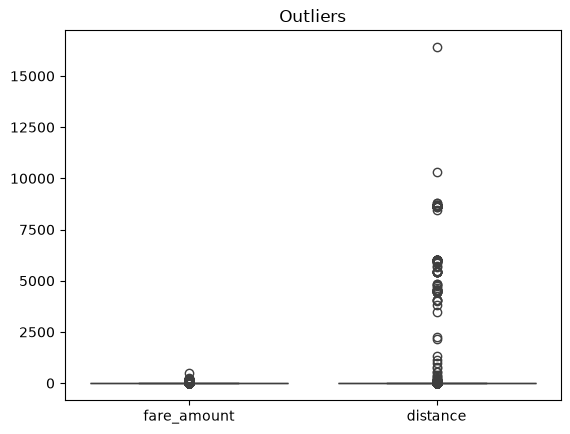

Shape after removing outliers: (169023, 12)


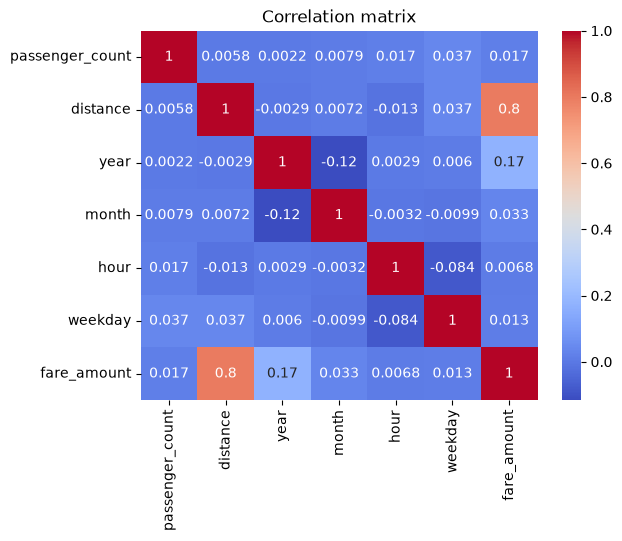

    Model  R2 score    RMSE
0  Linear    0.6626  2.1604
1   Ridge    0.6626  2.1605
2   Lasso    0.6243  2.2798


In [5]:
# Experiment 1: Regression Analysis - Uber Fare Prediction
# Aim: Predict the Uber fare using Linear, Ridge and Lasso regression.
# Steps: pre-process, find outliers, check correlation, compare the models.
# Dataset: uber.csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('uber.csv')
df = df.drop(['Unnamed: 0', 'key'], axis=1, errors='ignore')
df = df.dropna()

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['year'] = df['pickup_datetime'].dt.year
df['month'] = df['pickup_datetime'].dt.month
df['hour'] = df['pickup_datetime'].dt.hour
df['weekday'] = df['pickup_datetime'].dt.weekday

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df['distance'] = haversine(df['pickup_latitude'], df['pickup_longitude'],
                           df['dropoff_latitude'], df['dropoff_longitude'])

df = df[(df['fare_amount'] > 0) & (df['distance'] > 0) & (df['passenger_count'].between(1, 6))]

sns.boxplot(data=df[['fare_amount', 'distance']])
plt.title('Outliers')
plt.show()

for col in ['fare_amount', 'distance']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    df = df[(df[col] >= q1 - 1.5 * iqr) & (df[col] <= q3 + 1.5 * iqr)]
print("Shape after removing outliers:", df.shape)

features = ['passenger_count', 'distance', 'year', 'month', 'hour', 'weekday']
sns.heatmap(df[features + ['fare_amount']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation matrix')
plt.show()

X = df[features]
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

models = {'Linear': LinearRegression(), 'Ridge': Ridge(alpha=1000), 'Lasso': Lasso(alpha=0.5)}

result = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    result.append([name, r2_score(y_test, pred), np.sqrt(mean_squared_error(y_test, pred))])

print(pd.DataFrame(result, columns=['Model', 'R2 score', 'RMSE']).round(4))